<a href="https://colab.research.google.com/github/valeriacg410-sudo/Activities/blob/main/Activities/Decision_Tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Assignment 4 - Supervised learning model: Decision tree

Alisson Michelle Sepúlveda Torres 2115253
Mariana Vázquez De León 2114697
Valeria Cruz Gálvez 2001021
María Fernanda Tinoco Lopez 2103898

Class Time: N4

The student will train a decision tree model in Google Colab using the Python programming language. This model will use the "Breast Cancer Wisconsin (Diagnostic)" dataset; this dataset contains features computed from digitized images of breast cancer tumors and the corresponding diagnosis (malignant or benign).

## 1. Load libraries

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## 2. Load data.

In [2]:
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target

In [3]:
print("Number of samples and features:", X.shape)
print("Classes:", cancer.target_names)
print("First 5 features:", cancer.feature_names[:5])

Number of samples and features: (569, 30)
Classes: ['malignant' 'benign']
First 5 features: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness']


## 3. Data preprocessing

In [4]:
# Split the data: 80% training, 20% testing
train_data, test_data, train_labels, test_label = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

Training samples: 455
Testing samples: 114


## 4. Model selection and training

In [5]:
clf = DecisionTreeClassifier(random_state=42)
clf.fit(train_data, train_labels);

In [6]:
# Model accuracy on the training data
train_accuracy = clf.score(train_data, train_labels)
print("Training accuracy:", train_accuracy)

Training accuracy: 1.0


## 5. Model testing

In [7]:
# Predictions on the test data
test_pred = clf.predict(test_data)

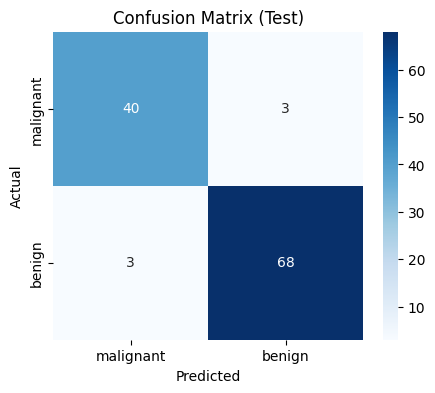

In [8]:
# Confusion matrix of the test results
conf_matrix = confusion_matrix(test_label, test_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=cancer.target_names, yticklabels=cancer.target_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (Test)")
plt.show()

In [9]:
accuracy = accuracy_score(test_label, test_pred)
print("Accuracy:", accuracy)
print("Classification Report:\n", classification_report(test_label, test_pred, target_names=cancer.target_names))

Accuracy: 0.9473684210526315
Classification Report:
               precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        43
      benign       0.96      0.96      0.96        71

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



## Decision tree visualization

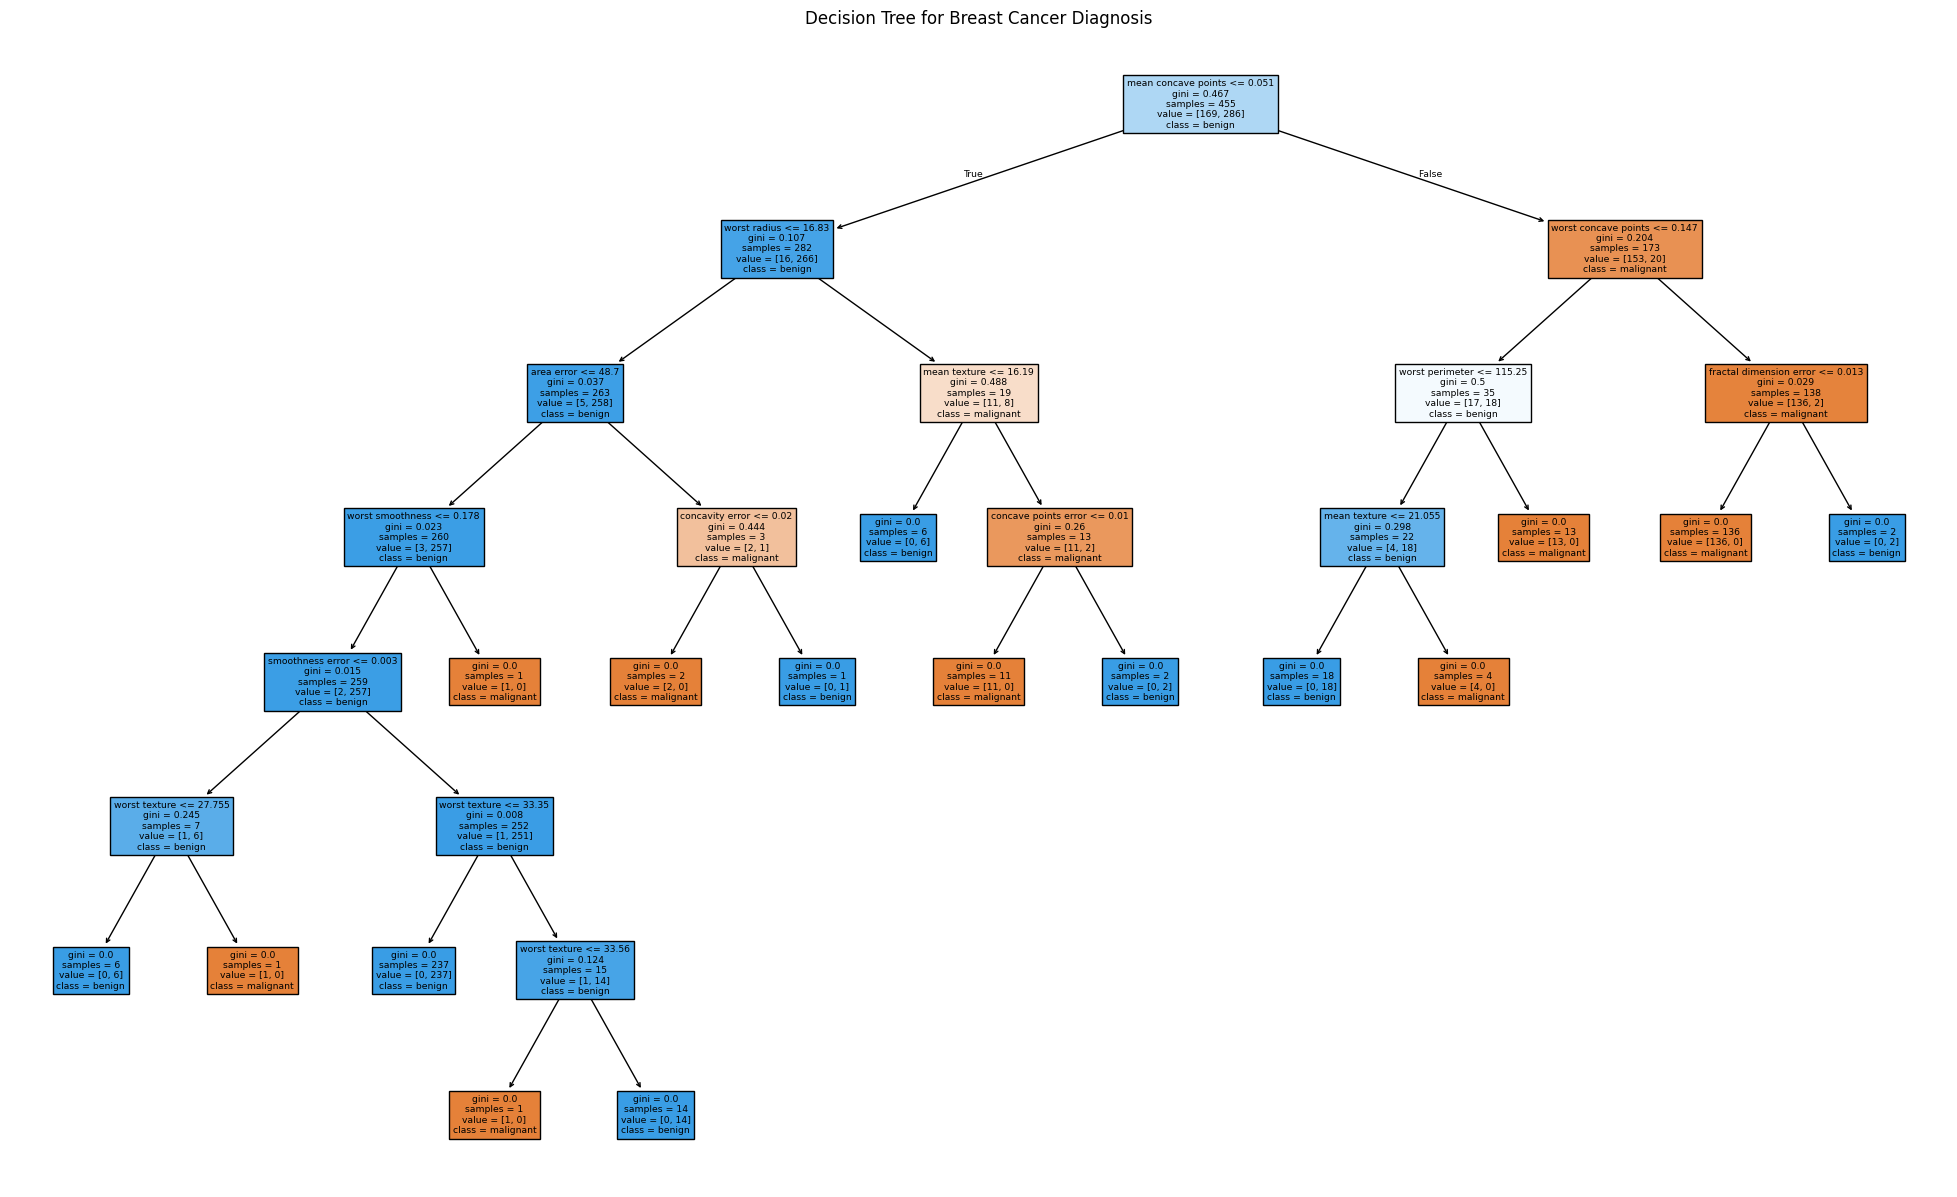

In [10]:
plt.figure(figsize=(25, 15))
tree.plot_tree(clf, filled=True, feature_names=cancer.feature_names, class_names=cancer.target_names)
plt.title("Decision Tree for Breast Cancer Diagnosis")
plt.savefig("decision_tree.png", dpi=300)
plt.show()